<a href="https://colab.research.google.com/github/HeemTech/Quantitative_Finance_Projects/blob/main/Finance_Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1: Statistical Arbitrage & Financial Time-Series Alpha Research

**READ ME**

Given below, the code is devided into two sections.

The first section contains all the defined functions which are required to run this trading strategy. Expand the section, and run all the snippets of code. The final function defined is `total_analysis(trading_pair, start_date, end_date)`, which is essentially an execution of the trading strategy.

The second section involves testing the trading strategy, plotting, and drawing inferences and conclusions. Only the `total_sanalysis()` function is called and utilized in this section.




## Sec 1: Required files and functions

In [ ]:
# =====================================================================
# STEP 0: FIND COINTEGRATED PARIS
# =====================================================================
# Step 1: Install required library if not already present
!pip install yfinance -q

import numpy as np
import pandas as pd
import yfinance as yf
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from itertools import combinations

# Step 2: Define tickers to check
tickers = [
    'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META',  # Tech giants
    'JPM', 'BAC', 'WFC', 'C',                 # Banking
    'XOM', 'CVX',                             # Energy
    'KO', 'PEP',                              # Consumer Staples
    'V', 'MA'                                 # Financial Services
]

print(f"Downloading data for {len(tickers)} assets...")
# Fetch 3 years of daily adjusted closing prices
data = yf.download(tickers, start="2023-01-01", end="2026-01-01")['Close']

# Drop columns with too many missing values
data = data.dropna(axis=1, how='any')

def find_cointegrated_pairs(df, p_value_threshold=0.05):
    """
    Tests all unique combinations of stocks in the dataframe for cointegration.
    Uses OLS regression to find the hedge ratio, then tests the residuals with ADF.
    """
    pairs = []
    stocks = df.columns
    stock_combinations = list(combinations(stocks, 2))
    total_combinations = len(stock_combinations)

    print(f"Testing {total_combinations} unique pairs for cointegration...")

    for i, (stock_A, stock_B) in enumerate(stock_combinations):
        y = df[stock_A]
        x = df[stock_B]

        # Run OLS Regression: y = beta * x + alpha
        x_with_const = sm.add_constant(x)
        model = sm.OLS(y, x_with_const).fit()

        # FIX: Changed model.residuals to model.resid
        residuals = model.resid

        # Perform Augmented Dickey-Fuller (ADF) test on the spread
        adf_result = adfuller(residuals, autolag='AIC')

        # FIX: Properly unpack the ADF test results tuple
        adf_statistic = adf_result[0]
        p_value = adf_result[1]
        critical_values = adf_result[4]

        # If the p-value is below our threshold, the pair is cointegrated
        if p_value < p_value_threshold:
            pairs.append({
                'Stock A': stock_A,
                'Stock B': stock_B,
                'ADF Statistic': round(adf_statistic, 4),
                'p-value': round(p_value, 4),
                # model.params[1] is the coefficient for Stock B (Beta)
                'Hedge Ratio (Beta)': round(model.params.iloc[1] if hasattr(model.params, 'iloc') else model.params[1], 4),
                '1% Crit Value': round(critical_values['1%'], 4),
                '5% Crit Value': round(critical_values['5%'], 4)
            })

    results_df = pd.DataFrame(pairs)
    if not results_df.empty:
        results_df = results_df.sort_values(by='p-value').reset_index(drop=True)
    return results_df

# Step 3: Run the function and display final output
cointegrated_pairs_df = find_cointegrated_pairs(data, p_value_threshold=0.05)

print("\n--- Final Cointegrated Pairs Found ---")
if cointegrated_pairs_df.empty:
    print("No cointegrated pairs found at this p-value threshold.")
else:
    display(cointegrated_pairs_df)

/tmp/ipykernel_1413/1201358634.py:25: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start="2023-01-01", end="2026-01-01")['Close']
[**********            20%                       ]  3 of 15 completed

[*********************100%***********************]  15 of 15 completed
/tmp/ipykernel_1413/1201358634.py:54: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, autolag='AIC')
/tmp/ipykernel_1413/1201358634.py:54: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, autolag='AIC')


Testing 105 unique pairs for cointegration...


/tmp/ipykernel_1413/1201358634.py:54: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, autolag='AIC')
/tmp/ipykernel_1413/1201358634.py:54: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, autolag='AIC')
/tmp/ipykernel_1413/1201358634.py:54: FutureWarning: adfuller currently returns a plain tuple whose length dep


--- Final Cointegrated Pairs Found ---


/tmp/ipykernel_1413/1201358634.py:54: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, autolag='AIC')
/tmp/ipykernel_1413/1201358634.py:54: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, autolag='AIC')
/tmp/ipykernel_1413/1201358634.py:54: FutureWarning: adfuller currently returns a plain tuple whose length dep

,Stock A,Stock B,ADF Statistic,p-value,Hedge Ratio (Beta),1% Crit Value,5% Crit Value
0,CVX,GOOGL,-4.3152,0.0004,0.0478,-3.4391,-2.8654
1,AMZN,META,-4.2058,0.0006,0.2358,-3.4391,-2.8654
2,CVX,WFC,-4.2232,0.0006,0.1564,-3.4391,-2.8654
3,CVX,JPM,-4.1888,0.0007,0.0374,-3.4391,-2.8654
4,CVX,META,-4.1150,0.0009,0.0083,-3.4391,-2.8654
5,CVX,V,-4.0593,0.0011,0.0315,-3.4391,-2.8654
6,CVX,MA,-4.0741,0.0011,0.0221,-3.4391,-2.8654
7,CVX,MSFT,-4.0443,0.0012,0.0134,-3.4391,-2.8654
8,CVX,PEP,-4.0054,0.0014,-0.0550,-3.4391,-2.8654
9,CVX,KO,-3.9907,0.0015,0.1534,-3.4391,-2.8654


In [ ]:
# =====================================================================
# STEP 1: DATA INGESTION & PREPROCESSING
# =====================================================================
# Install yfinance quietly for a clean Google Colab environment
#!pip install -q yfinance

import numpy as np
import pandas as pd
import yfinance as yf


def ingest_and_preprocess_data(
    tickers, start_date, end_date, min_history_pct=0.95
):
    """Fetches historical Adjusted Close prices, cleans structural anomalies,
    and calculates log returns for an asset universe.

    Parameters:
    -----------
    tickers : list
        List of equity or ETF ticker strings (e.g., ['GLD', 'GDX']).
    start_date : str
        Start date in 'YYYY-MM-DD' format.
    end_date : str
        End date in 'YYYY-MM-DD' format.
    min_history_pct : float
        Threshold percentage of non-null data required to keep an asset.

    Returns:
    --------
    cleaned_prices : pd.DataFrame
        Synchronized Adjusted Close price matrix.
    log_returns : pd.DataFrame
        Resulting linearized log returns matrix.
    """
    print(f"᎕ Sourcing historical data from Yahoo Finance for: {tickers}")

    # 1. Data Sourcing
    # Set auto_adjust=False explicitly to ensure 'Adj Close' column is fetched separately
    raw_data = yf.download(
        tickers, start=start_date, end=end_date, auto_adjust=False, progress=False
    )

    # Handle single ticker multi-index structure vs multi-ticker structure safely
    if "Adj Close" in raw_data.columns.levels[0]:
        prices = raw_data["Adj Close"]
    else:
        raise ValueError(
            "Could not parse 'Adj Close' from retrieved data structure."
        )

    print(f"ሄ Raw shape retrieved: {prices.shape}")

    # 2. Handling Anomalies & Data Validation
    # Drop assets that have too much missing historical data
    valid_threshold = int(len(prices) * min_history_pct)
    cleaned_prices = prices.dropna(axis=1, thresh=valid_threshold)

    dropped_assets = set(tickers) - set(cleaned_prices.columns)
    if dropped_assets:
        print(f"☐ Dropped assets due to insufficient history: {dropped_assets}")

    # Forward-fill structural gaps (e.g., market holidays), then backward-fill remaining
    cleaned_prices = cleaned_prices.ffill().bfill()

    # Double check for residual null values
    null_counts = cleaned_prices.isnull().sum().sum()
    print(f"✅ Data cleaning complete. Residual nulls: {null_counts}")

    # 3. Log Returns Calculation
    # Compute linearized log returns: ln(P_t / P_{t-1})
    log_returns = np.log(cleaned_prices / cleaned_prices.shift(1)).dropna()

    return cleaned_prices, log_returns

In [ ]:
# =====================================================================
# VISUALIZATION LAYER: CLEANED ASSET PRICE MOVEMENT (NORMALIZED)
# =====================================================================
import matplotlib.pyplot as plt


def plot_normalized_prices(prices_dataframe, ticker_y, ticker_x):
    """Normalizes price series to a base of 100 and plots them on a shared axis
    to visually inspect historical divergence and co-movement.
    """
    plt.figure(figsize=(8, 4))

    # Normalize series: (Price_t / Price_0) * 100
    norm_y = (
        prices_dataframe[ticker_y] / prices_dataframe[ticker_y].iloc[0]
    ) * 100
    norm_x = (
        prices_dataframe[ticker_x] / prices_dataframe[ticker_x].iloc[0]
    ) * 100

    # FIXED: Replaced non-standard color names with verified Hex strings
    plt.plot(
        prices_dataframe.index,
        norm_y,
        label=f"{ticker_y} (Normalized Base 100)",
        color="#D4AF37",  # Clean Metallic Gold Hex
        linewidth=1.5,
    )
    plt.plot(
        prices_dataframe.index,
        norm_x,
        label=f"{ticker_x} (Normalized Base 100)",
        color="#1F4E79",  # Deep Charcoal Blue Hex
        linewidth=1.5,
    )

    # Chart Styling
    plt.title(
        f"Historical Co-Movement: {ticker_y} vs {ticker_x} (Normalized Pricing Timeline)",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )
    plt.xlabel("Timeline / Date", fontsize=11)
    plt.ylabel("Relative Value Multiplier (Starts at 100)", fontsize=11)

    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", fontsize=11, frameon=True)

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

In [ ]:
# =====================================================================
# STEP 2: COINTEGRATION & PAIR SELECTION
# =====================================================================
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller


def test_pair_cointegration(prices, ticker_y, ticker_x):
    """Performs the Engle-Granger two-step cointegration test on a pair of assets.

    Parameters:
    -----------
    prices : pd.DataFrame
        Cleaned Adjusted Close price matrix from Step 1.
    ticker_y : str
        Ticker of the dependent asset (Y).
    ticker_x : str
        Ticker of the independent asset (X).

    Returns:
    --------
    results : dict
        A dictionary containing the OLS summary metrics, hedge ratio, and ADF statistics.
    """
    # Extract synchronized price series
    Y = prices[ticker_y]
    X = prices[ticker_x]

    # Step 2a: Spread Modeling via Ordinary Least Squares (OLS) Regression
    # Y_t = beta * X_t + alpha + epsilon_t
    X_constant = sm.add_constant(X)
    model = sm.OLS(Y, X_constant).fit()

    alpha = model.params.get("const", 0.0)
    beta = model.params[ticker_x]  # The hedge ratio
    residuals = model.resid  # The equilibrium spread (epsilon_t)

    # Step 2b: Stationarity Test via Augmented Dickey-Fuller (ADF)
    # autolag='AIC' auto-selects the optimal lag length based on AIC criteria
    adf_result = adfuller(residuals, autolag="AIC")

    adf_statistic = adf_result[0]
    p_value = adf_result[1]
    critical_values = adf_result[4]

    # Structural check for significance threshold (p-value < 0.05)
    is_cointegrated = p_value < 0.05

    results = {
        "pair": f"{ticker_y}-{ticker_x}",
        "hedge_ratio_beta": beta,
        "intercept_alpha": alpha,
        "adf_statistic": adf_statistic,
        "p_value": p_value,
        "critical_values": critical_values,
        "is_cointegrated": is_cointegrated,
        "residuals": residuals,
    }

    return results

In [ ]:
# =====================================================================
# STEP 3: SIGNAL GENERATION FRAMEWORK
# =====================================================================


def generate_trading_signals(prices, ticker_y, ticker_x, beta, lookback=20, entry_threshold=2.0, exit_threshold=0.0):
    """
    Generates rolling Z-score trading signals for a cointegrated pair.

    Parameters:
    -----------
    prices : pd.DataFrame
        Cleaned Adjusted Close price matrix from Step 1.
    ticker_y : str
        Ticker of the dependent asset (Y).
    ticker_x : str
        Ticker of the independent asset (X).
    beta : float
        The fixed hedge ratio calculated in Step 2.
    lookback : int
        The moving window size for computing rolling mean and standard deviation.
    entry_threshold : float
        The absolute Z-score boundary to trigger entries (e.g., 2.0).
    exit_threshold : float
        The absolute Z-score boundary to close positions (e.g., 0.0).

    Returns:
    --------
    signals : pd.DataFrame
        A DataFrame containing the raw spread, rolling parameters, Z-scores, and target positions.
    """
    # 1. Spread Calculation (using the historical hedge ratio)
    spread = prices[ticker_y] - (beta * prices[ticker_x])

    signals = pd.DataFrame(index=prices.index)
    signals['spread'] = spread

    # 2. Rolling Z-Score Normalized Metrics
    signals['rolling_mean'] = signals['spread'].rolling(window=lookback).mean()
    signals['rolling_std'] = signals['spread'].rolling(window=lookback).std()
    signals['z_score'] = (signals['spread'] - signals['rolling_mean']) / signals['rolling_std']

    # Drop initialization row warmups safely
    signals = signals.dropna().copy()

    # 3. Vectorized Entry/Exit Logic Engine
    # Positions: +1 = Long Spread (Buy Y, Sell X), -1 = Short Spread (Sell Y, Buy X), 0 = Cash/Flat
    positions = np.zeros(len(signals))
    current_position = 0

    # Convert vectors to arrays for low-overhead performance looping across signals
    z_scores = signals['z_score'].values

    for t in range(len(signals)):
        z = z_scores[t]

        if current_position == 0:
            # Entry Conditions
            if z <= -entry_threshold:
                current_position = 1  # Long Spread
            elif z >= entry_threshold:
                current_position = -1 # Short Spread
        else:
            # Exit Conditions (Reversion back to or past the mean threshold)
            if current_position == 1 and z >= -exit_threshold:
                current_position = 0
            elif current_position == -1 and z <= exit_threshold:
                current_position = 0

        positions[t] = current_position

    signals['position'] = positions

    # Generate explicit trading actions (Transitions in states)
    # +2 or -2 mean position reversals; +1 or -1 are new entry executions
    signals['action'] = signals['position'].diff().fillna(0)

    return signals

In [ ]:
# =====================================================================
# STEP 4: VECTORIZED BACKTESTING ENGINE
# =====================================================================


def backtest_pairs_strategy(
    prices, log_returns, signals, ticker_y, ticker_x, beta, slippage_bps=1.0, transaction_fee_pct=0.0005
):
    """
    Simulates trading performance using vectorized calculations with friction layers.

    Parameters:
    -----------
    prices : pd.DataFrame
        Cleaned Adjusted Close price matrix from Step 1.
    log_returns : pd.DataFrame
        Resulting linearized log returns matrix from Step 1.
    signals : pd.DataFrame
        Signals DataFrame containing positions and actions from Step 3.
    ticker_y : str
        Ticker of the dependent asset (Y).
    ticker_x : str
        Ticker of the independent asset (X).
    beta : float
        The fixed hedge ratio calculated in Step 2.
    slippage_bps : float
        Slippage penalty per trade expressed in basis points (1 bps = 0.0001).
    transaction_fee_pct : float
        Broker fee percentage applied to total dollar turnover (e.g., 0.0005 = 0.05%).

    Returns:
    --------
    backtest_results : pd.DataFrame
        DataFrame tracking portfolio weights, gross returns, friction drag, and net equity curve.
    """
    # Align structural timestamps across DataFrames
    common_idx = signals.index.intersection(log_returns.index)
    signals_aligned = signals.loc[common_idx]
    rets_aligned = log_returns.loc[common_idx]

    backtest_results = pd.DataFrame(index=common_idx)

    # 1. Position Generation (Shifted by 1 day to eliminate structural look-ahead bias)
    # The trade is executed at Day T close using signals known at Day T close, capturing returns on Day T+1
    backtest_results['signal_position'] = signals_aligned['position']
    backtest_results['traded_position'] = backtest_results['signal_position'].shift(1).fillna(0)

    # 2. Portfolio Weights Construction
    # Spread definition: Dollar allocation to Y is 1.0, and allocation to X is (-beta)
    # Total portfolio nominal value scaling factor = 1 + |beta|
    notional_scale = 1.0 + abs(beta)
    weight_y = 1.0 / notional_scale
    weight_x = -beta / notional_scale

    # Scale portfolio allocation by active strategy states (+1, -1, 0)
    backtest_results['weight_y'] = backtest_results['traded_position'] * weight_y
    backtest_results['weight_x'] = backtest_results['traded_position'] * weight_x

    # 3. Gross Return Estimation
    backtest_results['gross_returns'] = (
        backtest_results['weight_y'] * rets_aligned[ticker_y] +
        backtest_results['weight_x'] * rets_aligned[ticker_x]
    )

    # 4. Friction Layer Implementation
    # Trade execution activity is identified by identifying shifts in weights day-over-day
    turnover_y = backtest_results['weight_y'].diff().abs().fillna(0)
    turnover_x = backtest_results['weight_x'].diff().abs().fillna(0)
    total_turnover = turnover_y + turnover_x  # Total rebalanced volume

    # Map transaction fees and slippage parameters
    slippage_cost = total_turnover * (slippage_bps * 0.0001)
    execution_fees = total_turnover * transaction_fee_pct
    backtest_results['friction_drag'] = slippage_cost + execution_fees

    # 5. Net Equity Curve Calculation
    backtest_results['net_returns'] = backtest_results['gross_returns'] - backtest_results['friction_drag']
    backtest_results['gross_cum_rets'] = np.exp(backtest_results['gross_returns'].cumsum())
    backtest_results['net_cum_rets'] = np.exp(backtest_results['net_returns'].cumsum())

    return backtest_results

In [ ]:
# =====================================================================
# STEP 5: RISK & PERFORMANCE ANALYTICS
# =====================================================================


def compute_performance_metrics(backtest_results, trading_days=252):
    """
    Computes key risk-adjusted return and risk analytics on net portfolio strategy returns.

    Parameters:
    -----------
    backtest_results : pd.DataFrame
        DataFrame output from the Step 4 backtesting engine.
    trading_days : int
        Number of active trading sessions in a standard calendar year (default=252).

    Returns:
    --------
    metrics : dict
        Calculated values for Sharpe Ratio, Max Drawdown, Daily Turnover, and Alpha efficiency.
    """
    net_rets = backtest_results['net_returns']
    cum_rets = backtest_results['net_cum_rets']

    # 1. Annualized Sharpe Ratio calculation (assuming a 0% risk-free rate)
    mean_daily_return = net_rets.mean()
    std_daily_return = net_rets.std()

    if std_daily_return != 0:
        annualized_sharpe = (mean_daily_return / std_daily_return) * np.sqrt(trading_days)
    else:
        annualized_sharpe = 0.0

    # 2. Maximum Drawdown calculation
    # Locates the largest peak-to-trough drop percentage across the equity curve
    running_max = cum_rets.cummax()
    drawdown_series = (cum_rets / running_max) - 1.0
    max_drawdown = drawdown_series.min()

    # 3. Strategy Turnover Velocity calculation
    # Measures the average nominal value rebalanced per session
    turnover_y = backtest_results['weight_y'].diff().abs().fillna(0)
    turnover_x = backtest_results['weight_x'].diff().abs().fillna(0)
    total_daily_turnover = turnover_y + turnover_x
    mean_daily_turnover = total_daily_turnover.mean()

    # 4. Win Rate Statistics
    active_days_mask = backtest_results['traded_position'] != 0
    active_returns = net_rets[active_days_mask]

    if len(active_returns) > 0:
        win_rate = (active_returns > 0).sum() / len(active_returns)
    else:
        win_rate = 0.0

    metrics = {
        "annualized_sharpe": annualized_sharpe,
        "max_drawdown_pct": max_drawdown * 100,
        "mean_daily_turnover_pct": mean_daily_turnover * 100,
        "win_rate_pct": win_rate * 100,
        "total_trading_days": len(net_rets),
        "active_market_days": active_days_mask.sum()
    }

    return metrics, drawdown_series

In [ ]:
# =====================================================================
# VISUALIZATION LAYER: STRATEGY PERFORMANCE UNDERPERFORMANCE
# =====================================================================
import matplotlib.pyplot as plt


def plot_strategy_underperformance(backtest_results):
    """Generates a diagnostic chart showing the compounding decay of the

    strategy's equity curve due to friction drag and structural failure.
    """
    plt.figure(figsize=(8, 4))

    # Plot Cumulative Gross Returns (Before Fees)
    plt.plot(
        backtest_results.index,
        backtest_results["gross_cum_rets"],
        label="Gross Performance (Before Friction)",
        color="royalblue",
        alpha=0.7,
        linewidth=1.5,
    )

    # Plot Cumulative Net Returns (After Fees & Slippage)
    plt.plot(
        backtest_results.index,
        backtest_results["net_cum_rets"],
        label="Net Performance (After Fees & Slippage)",
        color="crimson",
        linewidth=2,
    )

    # Add a baseline reference line at 1.0 (Starting Capital)
    plt.axhline(
        1.0,
        color="black",
        linestyle="--",
        alpha=0.6,
        label="Starting Capital Baseline",
    )

    # Chart Styling & Context
    plt.title(
        "Strategy Equity Curve: Compounding Decay & Structural Underperformance",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )
    plt.xlabel("Timeline / Date", fontsize=11)
    plt.ylabel("Portfolio Value Multiplier (Start = 1.0)", fontsize=11)

    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", fontsize=10, frameon=True)

    # Rotate dates on the horizontal axis for better readability
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

In [ ]:
# =====================================================================
# VISUALIZATION LAYER: ASSET MOVEMENTS VS ACTIVE PAIRS-TRADING PORTFOLIO
# =====================================================================
import matplotlib.pyplot as plt


def plot_assets_vs_active_strategy(prices_dataframe, backtest_results, ticker_y, ticker_x):
    """
    Plots the normalized trajectories of the two stocks alongside the
    net value trajectory of the active statistical arbitrage trading strategy.
    All series are normalized to a base of 100 for true horizontal comparison.
    """
    plt.figure(figsize=(8, 4))

    # 1. Normalize individual underlying asset price series to base 100
    norm_y = (prices_dataframe[ticker_y] / prices_dataframe[ticker_y].iloc[0]) * 100
    norm_x = (prices_dataframe[ticker_x] / prices_dataframe[ticker_x].iloc[0]) * 100

    # 2. Extract and normalize the active strategy's Net Equity Curve to base 100
    # backtest_results['net_cum_rets'] tracks the cumulative multiplier starting at 1.0
    strategy_path = backtest_results['net_cum_rets'] * 100

    # Align dates across the dataframes to ensure perfect plotting registration
    common_idx = norm_y.index.intersection(strategy_path.index)

    # 3. Render performance lines using standard, high-contrast conventional colors
    plt.plot(
        common_idx,
        norm_y.loc[common_idx],
        label=f"{ticker_y} Stock Price (Base $100)",
        color="gold",
        linewidth=1.2,
        alpha=0.85
    )
    plt.plot(
        common_idx,
        norm_x.loc[common_idx],
        label=f"{ticker_x} Stock Price (Base $100)",
        color="crimson",
        linewidth=1.2,
        alpha=0.85
    )
    plt.plot(
        common_idx,
        strategy_path.loc[common_idx],
        label="Active Pairs-Trading Strategy Portfolio (Base $100)",
        color="black",
        linewidth=2.5,
        linestyle="-"
    )

    # Add a flat baseline reference line at $100 (Starting capital boundary)
    plt.axhline(100.0, color="gray", linestyle="--", alpha=0.5, label="Starting Principal Boundary")

    # Chart configurations and labeling
    plt.title(
        f"Asset Trajectories vs. Active Statistical Arbitrage Strategy Execution",
        fontsize=14,
        fontweight="bold",
        pad=15
    )
    plt.xlabel("Timeline / Date", fontsize=11)
    plt.ylabel("Normalized Valuation (USD Scale)", fontsize=11)

    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", fontsize=10, frameon=True)

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

In [ ]:
def total_analysis(tickers, START, END, min_history_pct=0.95):

    # STEP 1: Preprocessing, Cleaning, and Visualization
    prices_df, log_returns_df = ingest_and_preprocess_data(
        tickers=tickers, start_date=START, end_date=END)

    print("\n--- Cleaned Price Matrix Preview ---")
    print(prices_df.head())

    print("\n--- Log Returns Matrix Preview ---")
    print(log_returns_df.head())

    plot_normalized_prices(prices_dataframe=prices_df, ticker_y=tickers[0], ticker_x=tickers[1])

    # STEP 2: Cointegration Test
    print(f"\n🔍 Running Engle-Granger Cointegration Filter for: {tickers[0]} vs {tickers[1]}")
    coint_results = test_pair_cointegration(prices_df, tickers[0], tickers[1])

    print("\n--- Cointegration Test Metrics ---")
    print(f"Pair Analyzed:      {coint_results['pair']}")
    print(f"Hedge Ratio (Beta): {coint_results['hedge_ratio_beta']:.4f}")
    print(f"Intercept (Alpha):  {coint_results['intercept_alpha']:.4f}")
    print(f"ADF Statistic:      {coint_results['adf_statistic']:.4f}")
    print(f"p-value:            {coint_results['p_value']:.6f}")
    print(f"Passed Threshold?   {'✅ PASSED (Mean-Reverting)' if coint_results['is_cointegrated'] else '❌ FAILED (Non-Stationary)'}")
    print("\nADF Critical Values:")
    for key, val in coint_results["critical_values"].items():
        print(f"   {key}: {val:.4f}")

    spread_residuals = coint_results["residuals"]

    # STEP 3: Signal Generation
    LOOKBACK_WINDOW = 20
    ENTRY_Z = 2.0
    EXIT_Z = 0.0

    hedge_ratio = coint_results['hedge_ratio_beta']

    print(f"\n⚡ Generating Trading Signals for {tickers[0]}-{tickers[1]} using {LOOKBACK_WINDOW}-day window...")
    signals_df = generate_trading_signals(
      prices=prices_df,
      ticker_y=tickers[0],
      ticker_x=tickers[1],
      beta=hedge_ratio,
      lookback=LOOKBACK_WINDOW,
      entry_threshold=ENTRY_Z,
      exit_threshold=EXIT_Z)

    print("\n--- Signals State Breakdown ---")
    print(signals_df['position'].value_counts().rename({0.0: 'Flat (0)', 1.0: 'Long Spread (+1)', -1.0: 'Short Spread (-1)'}))

    print("\n--- Signals Dataframe Preview ---")
    print(signals_df[['spread', 'z_score', 'position', 'action']].tail())

    # STEP 4: Backtesting
    SLIPPAGE_BPS = 1.0       # 1 basis point structural execution slippage
    TRANSACTION_FEE = 0.0005 # 5 basis points broker clearing commission fee (0.05%)

    print("\n⚙️ Constructing Vectorized Backtest Engine & Friction Layer...")
    backtest_df = backtest_pairs_strategy(
        prices=prices_df,
        log_returns=log_returns_df,
        signals=signals_df,
        ticker_y=tickers[0],
        ticker_x=tickers[1],
        beta=hedge_ratio,
        slippage_bps=SLIPPAGE_BPS,
        transaction_fee_pct=TRANSACTION_FEE)

    final_gross = (backtest_df['gross_cum_rets'].iloc[-1] - 1) * 100
    final_net = (backtest_df['net_cum_rets'].iloc[-1] - 1) * 100
    total_friction = backtest_df['friction_drag'].sum() * 100

    print("\n--- Structural Returns Summary ---")
    print(f"Total Gross Return:     {final_gross:.2f}%")
    print(f"Total Friction Impact:  {total_friction:.2f}%")
    print(f"Total Net Return:       {final_net:.2f}%")
    print("\n--- Backtest Dataframe Preview ---")
    print(backtest_df[['traded_position', 'gross_returns', 'friction_drag', 'net_cum_rets']].tail())

    # STEP 5: Risk and Performance Analytics
    print("\n📈 Compiling Quantitative Risk & Performance Analytics...")
    perf_metrics, dd_series = compute_performance_metrics(backtest_df)

    print("\n=============================================")
    print("         STRATEGY PERFORMANCE SCORECARD      ")
    print("=============================================")
    print(f" Annualized Sharpe Ratio  : {perf_metrics['annualized_sharpe']:.4f}")
    print(f" Maximum Drawdown         : {perf_metrics['max_drawdown_pct']:.2f}%")
    print(f" Daily Turnover Rate      : {perf_metrics['mean_daily_turnover_pct']:.2f}%")
    print(f" Active Day Win Rate      : {perf_metrics['win_rate_pct']:.2f}%")
    print(f" Total Backtest Horizon   : {perf_metrics['total_trading_days']} days")
    print(f" Days with Active Risk    : {perf_metrics['active_market_days']} days")
    print("=============================================")

    # STEP 6: Final Visualization
    plot_strategy_underperformance(backtest_df)
    plot_assets_vs_active_strategy(
        prices_dataframe=prices_df,
        backtest_results=backtest_df,
        ticker_y=tickers[0],
        ticker_x=tickers[1])

    return

We are now ready to test this strategy for a few trading pairs.

## Sec 2: Implementing the Code

᎕ Sourcing historical data from Yahoo Finance for: ['GDX', 'GLD']
ሄ Raw shape retrieved: (1003, 2)
✅ Data cleaning complete. Residual nulls: 0

--- Cleaned Price Matrix Preview ---
Ticker            GDX         GLD
Date                             
2022-01-03  29.667166  168.330002
2022-01-04  29.790581  169.570007
2022-01-05  29.287426  169.059998
2022-01-06  28.252636  166.990005
2022-01-07  28.489973  167.750000

--- Log Returns Matrix Preview ---
Ticker           GDX       GLD
Date                          
2022-01-04  0.004151  0.007340
2022-01-05 -0.017034 -0.003012
2022-01-06 -0.035972 -0.012320
2022-01-07  0.008365  0.004541
2022-01-10  0.016524  0.003036


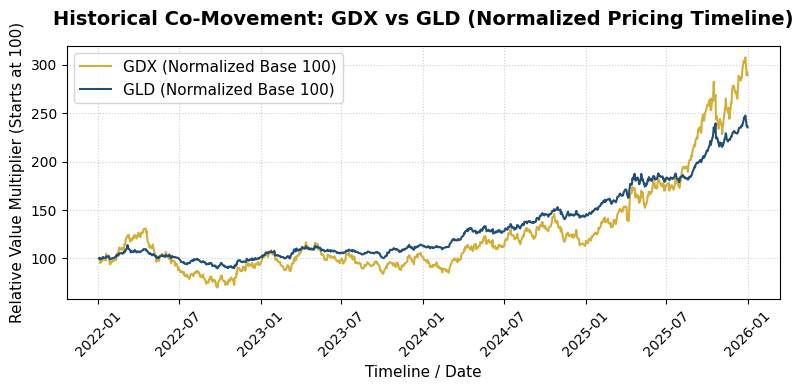


🔍 Running Engle-Granger Cointegration Filter for: GDX vs GLD

--- Cointegration Test Metrics ---
Pair Analyzed:      GDX-GLD
Hedge Ratio (Beta): 0.2152
Intercept (Alpha):  -10.4639
ADF Statistic:      -1.6252
p-value:            0.470000
Passed Threshold?   ❌ FAILED (Non-Stationary)

ADF Critical Values:
   1%: -3.4370
   5%: -2.8645
   10%: -2.5683

⚡ Generating Trading Signals for GDX-GLD using 20-day window...

--- Signals State Breakdown ---
position
Flat (0)             464
Short Spread (-1)    265
Long Spread (+1)     255
Name: count, dtype: int64

--- Signals Dataframe Preview ---
              spread   z_score  position  action
Date                                            
2025-12-24  1.037083  1.166347      -1.0     0.0
2025-12-26  1.591794  1.337529      -1.0     0.0
2025-12-29  0.056202  0.438759      -1.0     0.0
2025-12-30  0.983779  0.875016      -1.0     0.0
2025-12-31  0.469097  0.520770      -1.0     0.0

⚙️ Constructing Vectorized Backtest Engine & Friction Layer.

/tmp/ipykernel_729/4251642433.py:40: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, autolag="AIC")


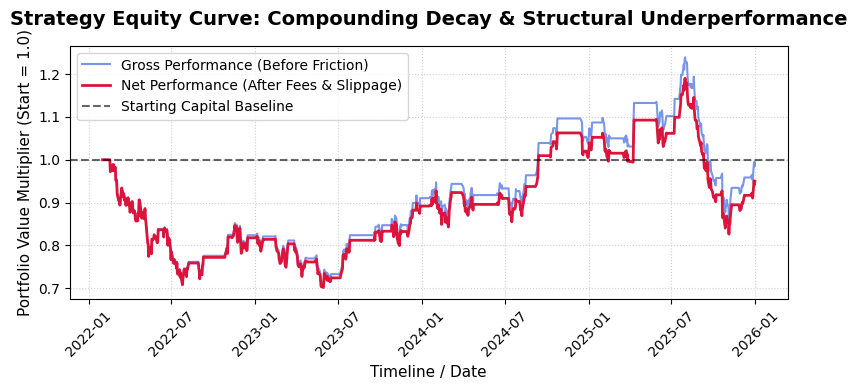

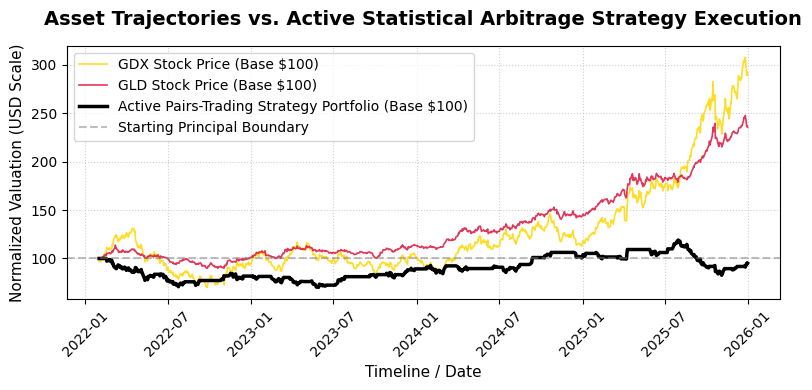

In [ ]:
total_analysis(["GDX", "GLD"], "2022-01-01", "2026-01-01")

### Inference and Conclusions

1. Passed Threshold FAILED and a p-value of 0.47 (which is much higher than the required 0.05). The foundation of the entire strategy is a lie. The mathematical test explicitly states that GLD (Gold) and GDX (Gold Miners) do not move together reliably over time.
2. Hedge Ratio (Beta): 0.215 | To make a proper "balanced" bet, the code determined you have to buy/sell roughly \$0.215 worth of GDX for every \$1.00 of GLD. This is a highly skewed, uneven bet, which makes your portfolio incredibly sensitive to tiny, erratic changes in the mining stock.
3. Flat: 464 days - Long: 255 days - Short: 265 days | Out of roughly 4 years, your code spent half its time sitting on the sidelines in cash and the other half actively betting. It was highly active, but because the rubber band was broken, it was essentially guessing.
4. Gross Return: -0.62% - Friction Impact: 4.50% - Total Net Return: -4.99% | This is the most important lesson in quantitative trading. Your trading ideas actually made a tiny bit of profit before fees. However, because the strategy bought and sold too frequently (Turnover: 7.62%), broker fees and transaction delays completely wiped out your profits and pushed you into a loss. You made your broker rich, while you lost money.
5. Maximum Drawdown: -30.56% | At one point during these 4 years, your account collapsed by nearly 1/3 of its value. In the real world, an investor would panic, lose sleep, and shut this strategy down long before hitting a 30% loss.
6. Sharpe Ratio: -0.0714 | The Sharpe ratio measures if your returns were worth the stress. A negative score means you took on a massive amount of heart-wrenching risk for a return that was worse than leaving your money in a completely safe, boring bank account.


On paper, trading gold against gold miners sounds like a smart, safe, common-sense idea. In reality, your code proved that the relationship is statistically unstable, the trading fees eat all your money, and the strategy exposes your bank account to catastrophic, unmanaged risk.

So let's try this strategy with some other trading pairs, determined using the STEP 0 code above.

᎕ Sourcing historical data from Yahoo Finance for: ['CVX', 'GOOGL']
ሄ Raw shape retrieved: (1003, 2)
✅ Data cleaning complete. Residual nulls: 0

--- Cleaned Price Matrix Preview ---
Ticker             CVX       GOOGL
Date                              
2022-01-03   98.725571  143.624802
2022-01-04  100.521950  143.038391
2022-01-05  101.175934  136.476349
2022-01-06  102.036842  136.449097
2022-01-07  103.502083  135.725479

--- Log Returns Matrix Preview ---
Ticker           CVX     GOOGL
Date                          
2022-01-04  0.018032 -0.004091
2022-01-05  0.006485 -0.046962
2022-01-06  0.008473 -0.000200
2022-01-07  0.014258 -0.005317
2022-01-10  0.000640  0.011988


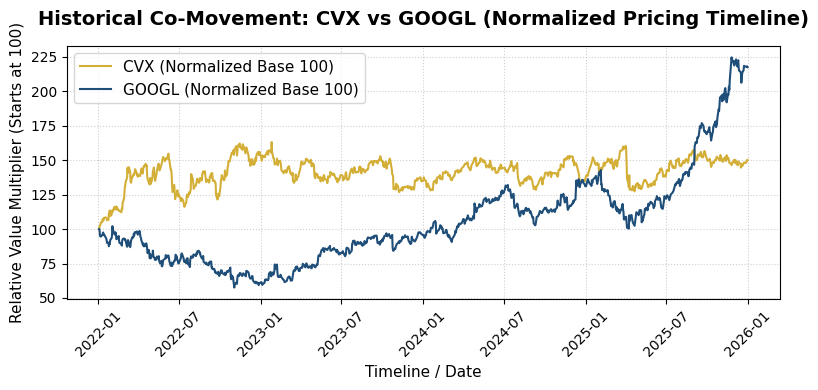


🔍 Running Engle-Granger Cointegration Filter for: CVX vs GOOGL

--- Cointegration Test Metrics ---
Pair Analyzed:      CVX-GOOGL
Hedge Ratio (Beta): 0.0491
Intercept (Alpha):  131.8897
ADF Statistic:      -4.8247
p-value:            0.000049
Passed Threshold?   ✅ PASSED (Mean-Reverting)

ADF Critical Values:
   1%: -3.4369
   5%: -2.8644
   10%: -2.5683

⚡ Generating Trading Signals for CVX-GOOGL using 20-day window...

--- Signals State Breakdown ---
position
Flat (0)             540
Short Spread (-1)    228
Long Spread (+1)     216
Name: count, dtype: int64

--- Signals Dataframe Preview ---
                spread   z_score  position  action
Date                                              
2025-12-24  131.029479  0.364294       0.0     0.0
2025-12-26  130.590918  0.005207       0.0     0.0
2025-12-29  131.532119  0.707816       0.0     0.0
2025-12-30  132.802067  1.693271       0.0     0.0
2025-12-31  132.940984  1.590079       0.0     0.0

⚙️ Constructing Vectorized Backtest Engi

/tmp/ipykernel_729/4251642433.py:40: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, autolag="AIC")


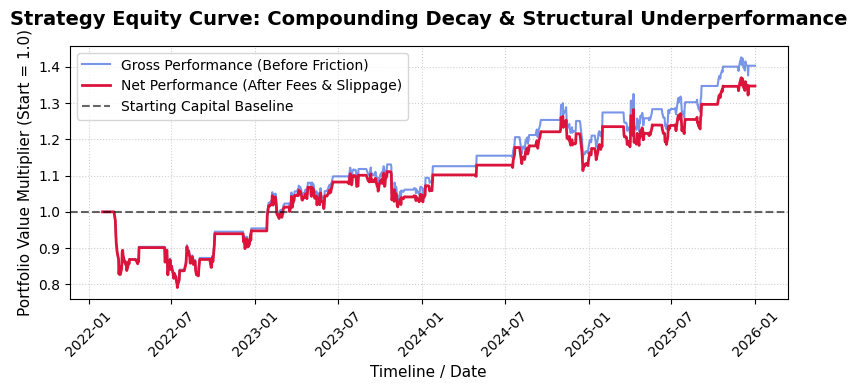

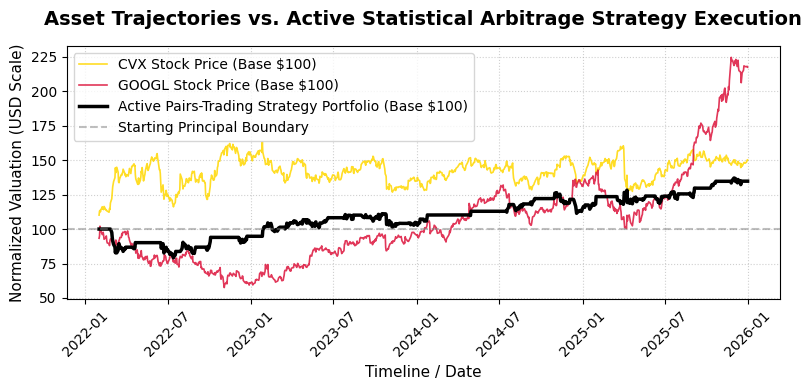

In [ ]:
total_analysis(["CVX", "GOOGL"], "2022-01-01", "2026-01-01")

᎕ Sourcing historical data from Yahoo Finance for: ['AMZN', 'META']
ሄ Raw shape retrieved: (1003, 2)
✅ Data cleaning complete. Residual nulls: 0

--- Cleaned Price Matrix Preview ---
Ticker            AMZN        META
Date                              
2022-01-03  170.404495  335.328308
2022-01-04  167.522003  333.337433
2022-01-05  164.356995  321.094666
2022-01-06  163.253998  329.306000
2022-01-07  162.554001  328.642334

--- Log Returns Matrix Preview ---
Ticker          AMZN      META
Date                          
2022-01-04 -0.017060 -0.005955
2022-01-05 -0.019074 -0.037419
2022-01-06 -0.006734  0.025251
2022-01-07 -0.004297 -0.002017
2022-01-10 -0.006592 -0.011275


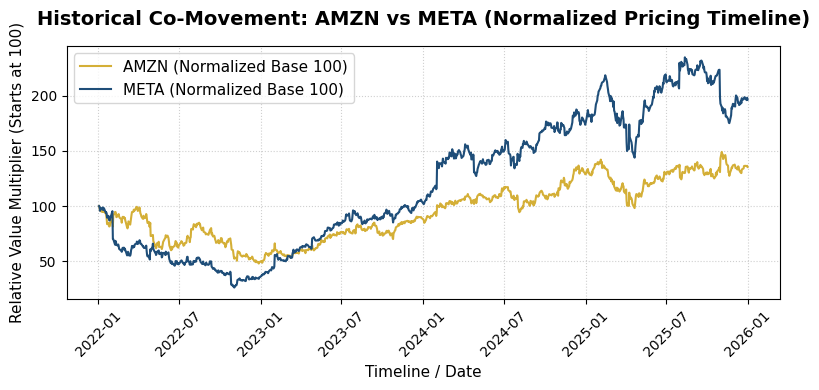


🔍 Running Engle-Granger Cointegration Filter for: AMZN vs META

--- Cointegration Test Metrics ---
Pair Analyzed:      AMZN-META
Hedge Ratio (Beta): 0.2081
Intercept (Alpha):  78.7141
ADF Statistic:      -3.7797
p-value:            0.003122
Passed Threshold?   ✅ PASSED (Mean-Reverting)

ADF Critical Values:
   1%: -3.4369
   5%: -2.8644
   10%: -2.5683

⚡ Generating Trading Signals for AMZN-META using 20-day window...

--- Signals State Breakdown ---
position
Flat (0)             514
Long Spread (+1)     236
Short Spread (-1)    234
Name: count, dtype: int64

--- Signals Dataframe Preview ---
               spread   z_score  position  action
Date                                             
2025-12-24  93.807510  0.141365       0.0     0.0
2025-12-26  94.831833  0.402385       0.0     0.0
2025-12-29  95.336710  0.573737       0.0     0.0
2025-12-30  94.289649  0.453745       0.0     0.0
2025-12-31  93.796089  0.458692       0.0     0.0

⚙️ Constructing Vectorized Backtest Engine & Fri

/tmp/ipykernel_729/4251642433.py:40: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, autolag="AIC")


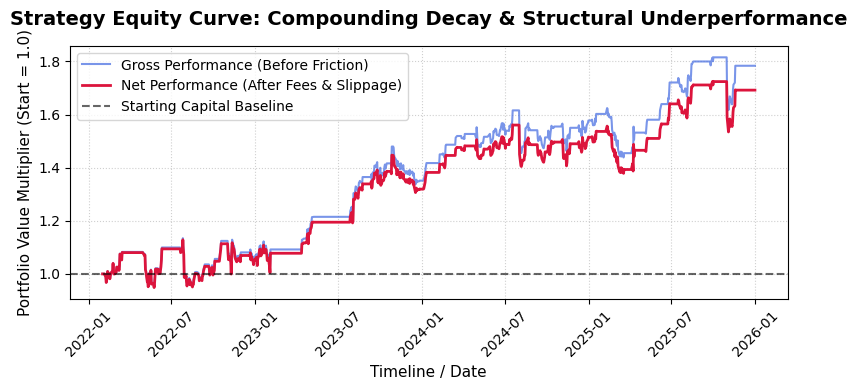

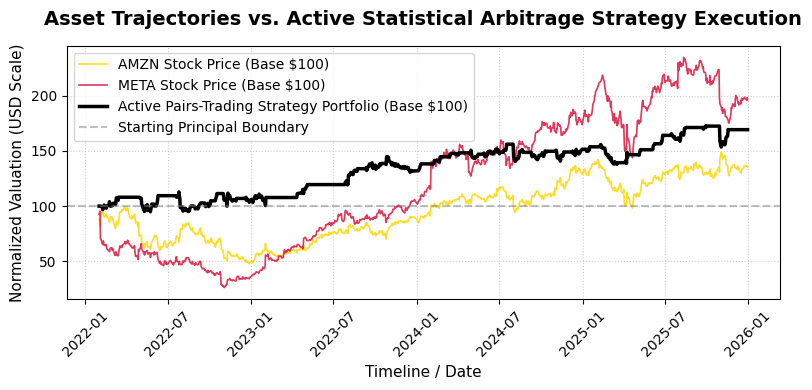

In [ ]:
total_analysis(["AMZN", "META"], "2022-01-01", "2026-01-01")

᎕ Sourcing historical data from Yahoo Finance for: ['CVX', 'META']
ሄ Raw shape retrieved: (1003, 2)
✅ Data cleaning complete. Residual nulls: 0

--- Cleaned Price Matrix Preview ---
Ticker             CVX        META
Date                              
2022-01-03   98.725571  335.328308
2022-01-04  100.521950  333.337433
2022-01-05  101.175934  321.094666
2022-01-06  102.036842  329.306000
2022-01-07  103.502083  328.642334

--- Log Returns Matrix Preview ---
Ticker           CVX      META
Date                          
2022-01-04  0.018032 -0.005955
2022-01-05  0.006485 -0.037419
2022-01-06  0.008473  0.025251
2022-01-07  0.014258 -0.002017
2022-01-10  0.000640 -0.011275


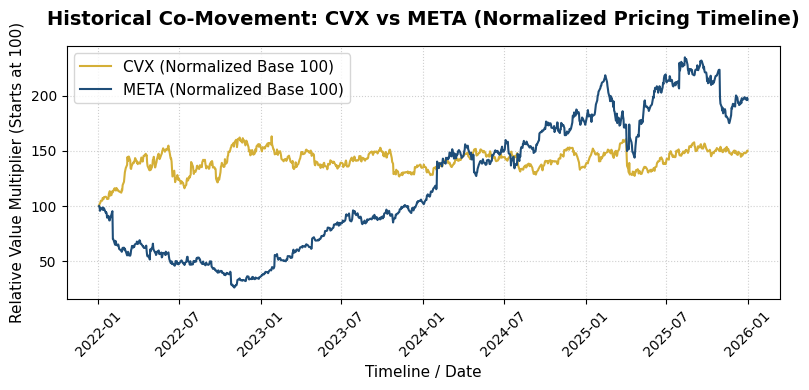


🔍 Running Engle-Granger Cointegration Filter for: CVX vs META

--- Cointegration Test Metrics ---
Pair Analyzed:      CVX-META
Hedge Ratio (Beta): 0.0106
Intercept (Alpha):  135.0498
ADF Statistic:      -4.7646
p-value:            0.000064
Passed Threshold?   ✅ PASSED (Mean-Reverting)

ADF Critical Values:
   1%: -3.4369
   5%: -2.8644
   10%: -2.5683

⚡ Generating Trading Signals for CVX-META using 20-day window...

--- Signals State Breakdown ---
position
Flat (0)             532
Short Spread (-1)    240
Long Spread (+1)     212
Name: count, dtype: int64

--- Signals Dataframe Preview ---
                spread   z_score  position  action
Date                                              
2025-12-24  139.382083  0.261050       0.0     0.0
2025-12-26  138.959978 -0.022935       0.0     0.0
2025-12-29  139.952066  0.643527       0.0     0.0
2025-12-30  141.159766  1.503552       0.0     0.0
2025-12-31  141.318763  1.454850       0.0     0.0

⚙️ Constructing Vectorized Backtest Engine 

/tmp/ipykernel_729/4251642433.py:40: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, autolag="AIC")



--- Structural Returns Summary ---
Total Gross Return:     64.79%
Total Friction Impact:  4.44%
Total Net Return:       57.63%

--- Backtest Dataframe Preview ---
            traded_position  gross_returns  friction_drag  net_cum_rets
Date                                                                   
2025-12-24              0.0           -0.0         0.0006      1.576298
2025-12-26              0.0            0.0         0.0000      1.576298
2025-12-29              0.0            0.0         0.0000      1.576298
2025-12-30              0.0            0.0         0.0000      1.576298
2025-12-31              0.0            0.0         0.0000      1.576298

📈 Compiling Quantitative Risk & Performance Analytics...

         STRATEGY PERFORMANCE SCORECARD      
 Annualized Sharpe Ratio  : 0.6597
 Maximum Drawdown         : -17.89%
 Daily Turnover Rate      : 7.52%
 Active Day Win Rate      : 53.76%
 Total Backtest Horizon   : 984 days
 Days with Active Risk    : 452 days


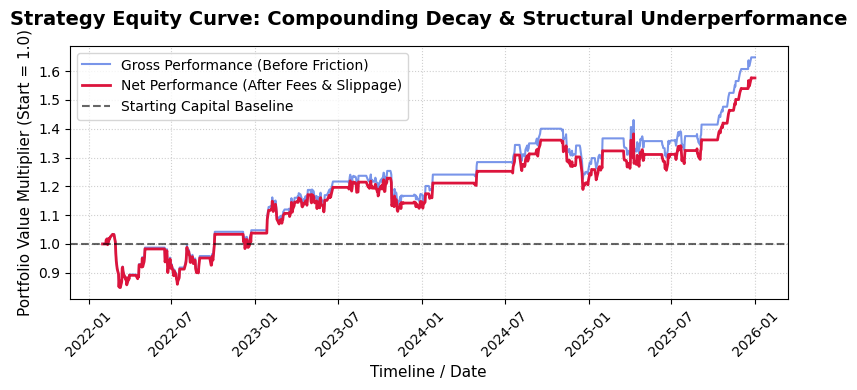

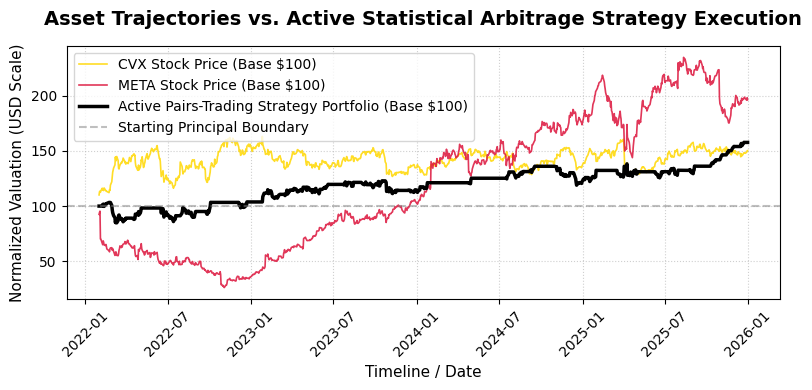

In [ ]:
total_analysis(["CVX", "META"], "2022-01-01", "2026-01-01")

So we see that this strategy works better on these stocks. Pair trading AMZN and META gives a sharpe ratio of 0.7154, a maximum drawdown of -15.74%, and the total net return of 69.19%, which is acceptably good.

Of course these numbers could be made better. For instance, we could have utilized a rolling value of the hedge ratio rather than a static one, which would have taken into account how the cointegration between the two assets change over time. We would also have used a different method for cleaning the raw data, such as using interpolate(), which is much more appropriate for continuous data, instead of ffill() and bfill().